In [1]:
from pathlib import Path
from math import erf, exp, log, sqrt
import numpy as np
import pandas as pd

root = Path.home() / "Desktop" / "Chooser_Option_Research"

aligned = pd.read_csv(
    root / "02_Data/processed/W02_Aligned_Market_Data.csv",
    parse_dates=["Date"]
)

features = pd.read_csv(
    root / "02_Data/processed/W02_Feature_Dataset.csv",
    parse_dates=["Date"]
)

print("Aligned data:", aligned.shape)
print("Feature data:", features.shape)

Aligned data: (1761, 13)
Feature data: (1741, 23)


In [2]:
# Historical valuation date
t0 = features["Date"].max()

row = features.loc[
    features["Date"] == t0
].iloc[0]

# Stock and option parameters
S0 = float(row["Close"])
K = S0

# Chooser timeline (in years)
T1 = 0.5
T2 = 1.0

# Historical volatility
sigma = float(row["volatility_20d"])

# Maturity-matched Treasury yield proxies
r_T1 = float(row["DGS6MO"])
r_T2 = float(row["DGS1"])

print("Valuation date:", t0.date())
print("Spot price:", S0)
print("Strike price:", K)
print("20-day volatility:", sigma)
print("6M Treasury rate:", r_T1)
print("1Y Treasury rate:", r_T2)

Valuation date: 2024-12-31
Spot price: 239.7100067138672
Strike price: 239.7100067138672
20-day volatility: 0.1866672202232296
6M Treasury rate: 0.0424
1Y Treasury rate: 0.0416


In [3]:
# Historical dividend window
start_date = t0 - pd.DateOffset(years=1)

dividends_1y = aligned.loc[
    (aligned["Date"] > start_date) &
    (aligned["Date"] <= t0),
    "Dividends"
].sum()

# Trailing dividend yield proxy
q = float(dividends_1y / S0)

print("Annual dividends per share:", dividends_1y)
print("Estimated dividend yield:", q)
print("Dividend yield (%):", round(q * 100, 3))

Annual dividends per share: 4.6
Estimated dividend yield: 0.019189853869933958
Dividend yield (%): 1.919


In [4]:
def norm_cdf(x):
    return 0.5 * (1.0 + erf(x / sqrt(2.0)))

In [5]:
def bsm_european(S, K, T, r, q, sigma):

    # Input validation
    if not np.all(np.isfinite([S, K, T, r, q, sigma])):
        raise ValueError("Inputs must be finite.")

    if S <= 0 or K <= 0 or T <= 0 or sigma <= 0:
        raise ValueError("S, K, T and sigma must be positive.")

    # BSM parameters
    d1 = (
        log(S / K) + (r - q + 0.5 * sigma**2) * T
    ) / (sigma * sqrt(T))

    d2 = d1 - sigma * sqrt(T)

    # European call
    call = (
        S * exp(-q * T) * norm_cdf(d1)
        - K * exp(-r * T) * norm_cdf(d2)
    )

    # European put
    put = (
        K * exp(-r * T) * norm_cdf(-d2)
        - S * exp(-q * T) * norm_cdf(-d1)
    )

    return call, put

In [6]:
call_price, put_price = bsm_european(
    S=S0,
    K=K,
    T=T2,
    r=r_T2,
    q=q,
    sigma=sigma
)

print(f"European Call Price: ${call_price:.4f}")
print(f"European Put Price:  ${put_price:.4f}")

European Call Price: $20.0223
European Put Price:  $14.8111


In [7]:
lhs = call_price - put_price

rhs = (
    S0 * exp(-q * T2)
    - K * exp(-r_T2 * T2)
)

error = abs(lhs - rhs)

print("Put-Call Parity Error:", error)

assert error < 1e-10

print("Put-Call Parity Test: PASSED")

Put-Call Parity Error: 0.0
Put-Call Parity Test: PASSED


In [8]:
call_no_div, put_no_div = bsm_european(
    S=S0,
    K=K,
    T=T2,
    r=r_T2,
    q=0.0,
    sigma=sigma
)

comparison = pd.DataFrame({
    "With Dividends": [call_price, put_price],
    "Without Dividends": [call_no_div, put_no_div]
}, index=["Call", "Put"])

display(comparison.round(4))

assert call_price <= call_no_div + 1e-10
assert put_price >= put_no_div - 1e-10

print("Dividend Sensitivity Test: PASSED")

,With Dividends,Without Dividends
Call,20.0223,22.7762
Put,14.8111,13.0089


Dividend Sensitivity Test: PASSED


## W03 Part 1 — BSM Baseline

**Underlying:** JPM  
**Valuation Date:** 2024-12-31  
**Contract:** Simple European Chooser (initial specification)

### Methodology
- Spot: Unadjusted closing price.
- Strike: At-the-money.
- Volatility: 20-day annualized historical volatility.
- Dividend yield: Trailing 12-month dividend yield proxy.
- Risk-free rates: 6M and 1Y Treasury maturity proxies.

### Validation
- Put–Call Parity
- Dividend Sensitivity

### Limitations
- Constant volatility assumption.
- Continuous dividend yield approximation.
- Treasury yields used as approximate discount rates.
- No observed Chooser Option market prices.

In [9]:
# Step 2: Estimate JPM dividend yield

start_date = t0 - pd.DateOffset(years=1)

dividend_records = aligned.loc[
    (aligned["Date"] > start_date) &
    (aligned["Date"] <= t0) &
    (aligned["Dividends"] > 0),
    ["Date", "Dividends"]
]

display(dividend_records)

dividends_1y = dividend_records["Dividends"].sum()

q = float(dividends_1y / S0)

print(f"Annual dividends per share: ${dividends_1y:.4f}")
print(f"Estimated dividend yield: {q:.6f}")
print(f"Dividend yield (%): {q * 100:.3f}%")

,Date,Dividends
1511,2024-01-04,1.05
1573,2024-04-04,1.15
1636,2024-07-05,1.15
1700,2024-10-04,1.25


Annual dividends per share: $4.6000
Estimated dividend yield: 0.019190
Dividend yield (%): 1.919%


In [10]:
# Step 1: Implied forward rate

delta_T = T2 - T1

forward_rate = (
    r_T2 * T2 - r_T1 * T1
) / delta_T

print(f"Remaining maturity: {delta_T:.2f} years")
print(f"Forward rate: {forward_rate:.4%}")

Remaining maturity: 0.50 years
Forward rate: 4.0800%


In [11]:
# Step 2: Critical stock price

S_star = K * exp((q - forward_rate) * delta_T)

print(f"Strike price: ${K:.4f}")
print(f"Critical stock price: ${S_star:.4f}")

Strike price: $239.7100
Critical stock price: $237.1339


In [12]:
# Verify the call/put decision at T1

def chooser_at_choice(S_T1):
    call, put = bsm_european(
        S=S_T1,
        K=K,
        T=delta_T,
        r=forward_rate,
        q=q,
        sigma=sigma
    )

    decision = "Call" if call >= put else "Put"

    return call, put, decision

for stock_price in [230, S_star, 245]:
    call, put, decision = chooser_at_choice(stock_price)

    print(
        f"S = ${stock_price:.2f} | "
        f"Call = ${call:.4f} | "
        f"Put = ${put:.4f} | "
        f"Decision = {decision}"
    )

S = $230.00 | Call = $8.9640 | Put = $16.0297 | Decision = Put
S = $237.13 | Call = $12.3587 | Put = $12.3587 | Decision = Call
S = $245.00 | Call = $16.8407 | Put = $9.0497 | Decision = Call


In [13]:
# Step 3: Simple Chooser BSM pricing

# Adjusted parameters
S_adjusted = S0 * exp(-q * delta_T)
K_adjusted = K * exp(-forward_rate * delta_T)

# Original European call and put
call_T2, put_T2 = bsm_european(
    S0, K, T2, r_T2, q, sigma
)

# Adjusted option expiring at choice date T1
extra_call, extra_put = bsm_european(
    S_adjusted,
    K_adjusted,
    T1,
    r_T1,
    q,
    sigma
)

# Simple Chooser price
chooser_price = call_T2 + extra_put

print(f"European Call: ${call_T2:.4f}")
print(f"European Put: ${put_T2:.4f}")
print(f"Additional choice value: ${extra_put:.4f}")
print(f"Simple Chooser Price: ${chooser_price:.4f}")

European Call: $20.0223
European Put: $14.8111
Additional choice value: $9.8067
Simple Chooser Price: $29.8290


In [14]:
assert chooser_price >= call_T2
assert chooser_price >= put_T2

print("Chooser price bound test: PASSED")

Chooser price bound test: PASSED


In [15]:
chooser_alternative = put_T2 + extra_call

print(f"Method 1: ${chooser_price:.6f}")
print(f"Method 2: ${chooser_alternative:.6f}")

assert np.isclose(
    chooser_price,
    chooser_alternative,
    atol=1e-10
)

print("Chooser decomposition test: PASSED")

Method 1: $29.829018
Method 2: $29.829018
Chooser decomposition test: PASSED


In [16]:
call_star, put_star, _ = chooser_at_choice(S_star)

assert np.isclose(
    call_star,
    put_star,
    atol=1e-10
)

print("Critical stock price test: PASSED")

Critical stock price test: PASSED


## W03 Part 2 — Simple Chooser Option Pricing

### Model
- European Simple Chooser Option
- Common strike and final expiration
- Choice date: T1 = 0.5 years
- Expiration date: T2 = 1.0 year

### Method
- Dividend-adjusted BSM pricing
- Forward-rate approximation from 6M and 1Y Treasury yields
- Put–Call Parity decomposition
- Critical stock price and optimal choice rule

### Validation
- Chooser price bounds
- Equivalent decomposition
- Critical stock price consistency

### Limitations
- Constant volatility and dividend-yield assumptions
- Approximate Treasury discount curve
- Theoretical price rather than observed market price

In [17]:
## Part 3 — Sensitivity Analysis and Model Validation
def chooser_bsm(S, K, T1, T2, r1, r2, q, sigma):

    if not 0 < T1 < T2:
        raise ValueError("Require 0 < T1 < T2")

    delta_T = T2 - T1

    # Implied forward rate
    f = (r2 * T2 - r1 * T1) / delta_T

    # European call expiring at T2
    call, _ = bsm_european(
        S, K, T2, r2, q, sigma
    )

    # Adjusted put expiring at T1
    S_adj = S * exp(-q * delta_T)
    K_adj = K * exp(-f * delta_T)

    _, put_adj = bsm_european(
        S_adj, K_adj, T1, r1, q, sigma
    )

    return call + put_adj

In [18]:
base_params = {
    "S": S0,
    "K": K,
    "T1": T1,
    "T2": T2,
    "r1": r_T1,
    "r2": r_T2,
    "q": q,
    "sigma": sigma
}

baseline = chooser_bsm(**base_params)

print(f"BSM Chooser Baseline: ${baseline:.4f}")

BSM Chooser Baseline: $29.8290


In [19]:
def price_with(**changes):
    params = base_params.copy()
    params.update(changes)
    return chooser_bsm(**params)

In [20]:
print(price_with(sigma=0.25))

39.735386343748786


In [21]:
def maturity_rate(t):

    if not T1 <= t <= T2:
        raise ValueError("Maturity outside available range")

    weight = (t - T1) / (T2 - T1)

    cumulative_rate = (
        (1 - weight) * r_T1 * T1
        + weight * r_T2 * T2
    )

    return cumulative_rate / t

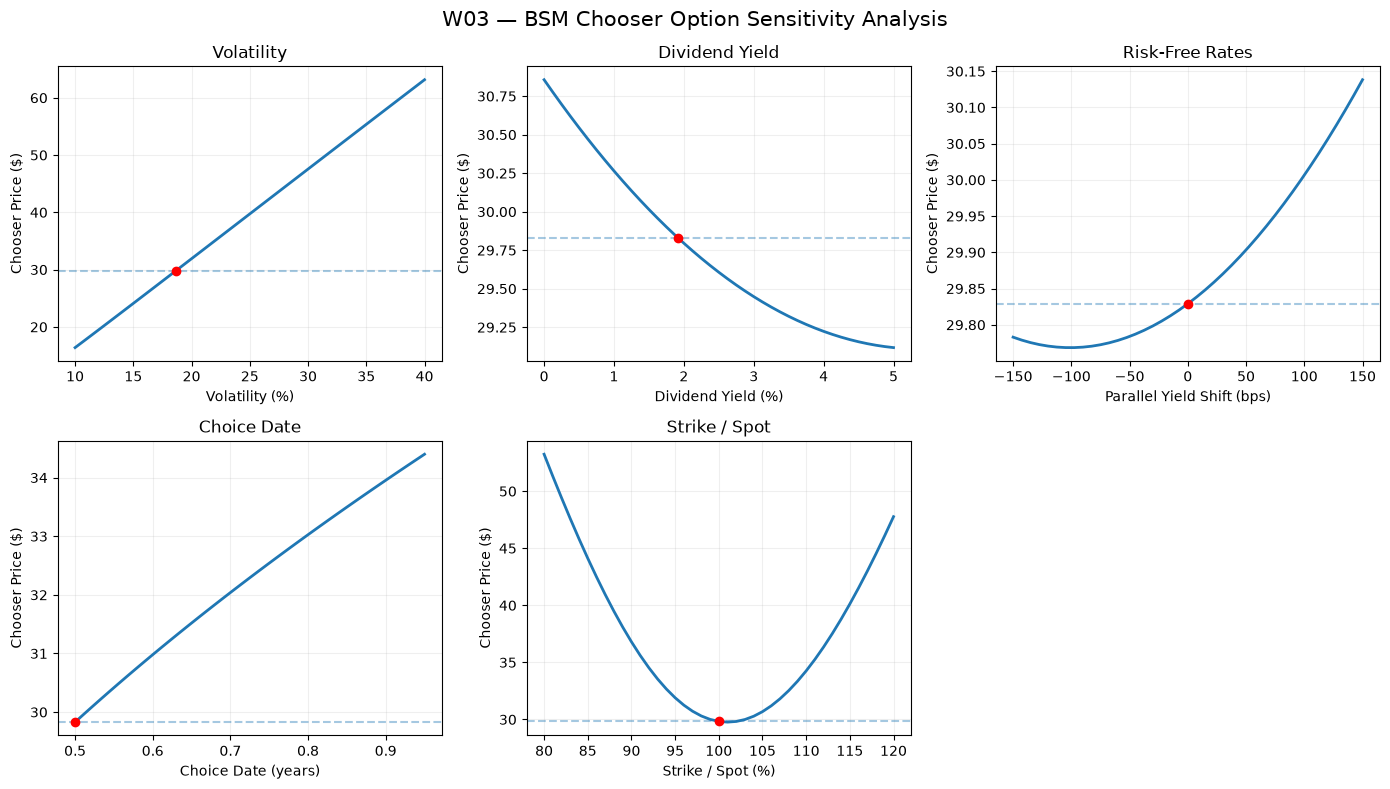

In [22]:
import matplotlib.pyplot as plt

# 1. Parameter ranges
sigma_grid = np.linspace(0.10, 0.40, 41)
q_grid = np.linspace(0.00, 0.05, 41)
rate_shifts = np.linspace(-0.015, 0.015, 41)
choice_dates = np.linspace(0.50, 0.95, 41)
strike_ratios = np.linspace(0.80, 1.20, 41)

# 2. Reprice under each scenario
sigma_prices = [
    price_with(sigma=x) for x in sigma_grid
]

q_prices = [
    price_with(q=x) for x in q_grid
]

rate_prices = [
    price_with(r1=r_T1 + x, r2=r_T2 + x)
    for x in rate_shifts
]

choice_prices = [
    price_with(T1=x, r1=maturity_rate(x))
    for x in choice_dates
]

strike_prices = [
    price_with(K=S0 * x)
    for x in strike_ratios
]

# 3. Plot configurations
panels = [
    ("Volatility", sigma_grid * 100,
     sigma_prices, "Volatility (%)", sigma * 100),

    ("Dividend Yield", q_grid * 100,
     q_prices, "Dividend Yield (%)", q * 100),

    ("Risk-Free Rates", rate_shifts * 10000,
     rate_prices, "Parallel Yield Shift (bps)", 0),

    ("Choice Date", choice_dates,
     choice_prices, "Choice Date (years)", T1),

    ("Strike / Spot", strike_ratios * 100,
     strike_prices, "Strike / Spot (%)", 100)
]

fig, axes = plt.subplots(2, 3, figsize=(14, 8))

for ax, (title, x, y, xlabel, x0) in zip(axes.flat, panels):

    ax.plot(x, y, linewidth=2)

    # Mark the original BSM benchmark
    ax.scatter([x0], [baseline], color="red", zorder=3)

    ax.axhline(
        baseline, linestyle="--", alpha=0.4
    )

    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Chooser Price ($)")
    ax.grid(alpha=0.2)

axes.flat[-1].axis("off")

fig.suptitle(
    "W03 — BSM Chooser Option Sensitivity Analysis",
    fontsize=15
)

plt.tight_layout()

In [23]:
fig_dir = root / "04_Reports/weekly/figures"
fig_dir.mkdir(parents=True, exist_ok=True)

fig.savefig(
    fig_dir / "W03_Chooser_Sensitivity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved:", (
    fig_dir / "W03_Chooser_Sensitivity.png"
).exists())

Figure saved: True


In [24]:
# 1. Chooser must be at least as valuable
#    as either standalone European option

call, put = bsm_european(
    S0, K, T2, r_T2, q, sigma
)

assert baseline >= max(call, put)

# 2. Two equivalent chooser decompositions

delta = T2 - T1
f = (r_T2 * T2 - r_T1 * T1) / delta

S_adj = S0 * exp(-q * delta)
K_adj = K * exp(-f * delta)

extra_call, extra_put = bsm_european(
    S_adj, K_adj, T1, r_T1, q, sigma
)

assert np.isclose(
    call + extra_put,
    put + extra_call,
    atol=1e-10
)

# 3. Choice date approaching final expiry
#    should approach a European straddle

late_T1 = T2 - 0.0001

late_choice_price = price_with(
    T1=late_T1,
    r1=maturity_rate(late_T1)
)

assert np.isclose(
    late_choice_price,
    call + put,
    atol=0.05
)

print("W03 Model Validation: PASSED")

W03 Model Validation: PASSED
